# Assignment 2: Exercise 1

To improve the learning stability, introduce (mini) batched learning.
(See Unit 3 Page 95 of the lecture for guidance). Compare the convergence behavior of batched
learning to online learning, dig deeper than just reporting the slowdown in convergence due to
fewer update steps.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Dict, Optional
from pyMLaux import plot_2d_prediction

## 1. Setup
First I will reuse the methods from the exercise, that are necessary.

### 1.1 Utilities

In [3]:
def one_hot(y: np.ndarray, num_classes: int) -> np.ndarray:
    oh = np.zeros((y.size, num_classes))
    oh[np.arange(y.size), y] = 1.0
    return oh

# Initialization helpers

# Activations and their derivatives

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def dsigmoid(z):
    s = sigmoid(z)
    return s * (1 - s)

# Stable softmax + cross-entropy

def softmax(logits: np.ndarray) -> np.ndarray:
    z = logits - logits.max(axis=1, keepdims=True)
    expz = np.exp(z)
    return expz / expz.sum(axis=1, keepdims=True)

def binary_cross_entropy(yhat: float, y_true: float, eps: float = 1e-12) -> float:
    yhat_clipped = np.clip(yhat, eps, 1.0)
    return -(y_true * np.log(yhat_clipped) + (1 - y_true) * np.log(1 - yhat_clipped))

def cross_entropy(probs: np.ndarray, y_true_oh: np.ndarray, eps: float = 1e-12) -> float:
    # Avoid log(0)
    p = np.clip(probs, eps, 1.0)
    return -np.mean(np.sum(y_true_oh * np.log(p), axis=1))


### 1.2. MLP Class

In [4]:
class MLP:
    def __init__(
        self,
        input_dim: int,
        layer_sizes: List[int],
        num_classes: int,
        seed: Optional[int] = None,
    ):
        self.rng = np.random.default_rng(seed)
        self.shapes = []

        self.act = sigmoid
        self.dact = dsigmoid

        # layer dimensions
        dims = [input_dim] + layer_sizes + [num_classes]
        self.L = len(dims) - 1

        # params init
        self.W = {}
        self.b = {}
        for k in range(1, self.L + 1):
            fan_in, fan_out = dims[k-1], dims[k]
            Wk = np.random.randn(fan_in, fan_out)
            bk = np.zeros((1, fan_out))
            self.W[k] = Wk
            self.b[k] = bk
            self.shapes.append((fan_in, fan_out))

    def forward(self, X: np.ndarray, train: bool = True):
        caches = []
        A = X
        for k in range(1, self.L + 1):
            Z = A @ self.W[k] + self.b[k]
            if k == self.L:
                A_next = softmax(Z)
            else:
                A_next = self.act(Z)
            caches.append((Z, A, self.W[k], self.b[k]))
            A = A_next
        return A, caches

    def backward(self, probs: np.ndarray, y_onehot: np.ndarray, caches: List[tuple]):
        grads_W = {}
        grads_b = {}
        m = y_onehot.shape[0]

        # Initial gradient at output: softmax + cross-entropy
        dA = (probs - y_onehot) / m  # shape (m, C)

        for k in reversed(range(1, self.L + 1)):
            Z, A_prev, Wk, bk = caches[k-1]
            dZ = dA  # start with upstream gradient
            if k != self.L:
                # back through activation
                dZ = dZ * self.dact(Z)

            # linear layer grads
            dW = A_prev.T @ dZ
            db = np.sum(dZ, axis=0, keepdims=True)
            dA = dZ @ Wk.T

            grads_W[k] = dW
            grads_b[k] = db
        return grads_W, grads_b

    def step(self, grads_W: Dict[int, np.ndarray], grads_b: Dict[int, np.ndarray], lr: float):
        for k in range(1, self.L + 1):
            self.W[k] -= lr * grads_W[k]
            self.b[k] -= lr * grads_b[k]

    def compute_loss(self, probs: np.ndarray, y_onehot: np.ndarray):
        loss = cross_entropy(probs, y_onehot)
        return loss

    def predict(self, X: np.ndarray):
        probs, _ = self.forward(X, train=False)
        return np.argmax(probs, axis=1), probs


### 1.3 Training function

In [5]:
def accuracy(y_true, y_pred):
    return (y_true == y_pred).mean()


def train_online_learning(
    model: MLP,
    X: np.ndarray,
    y: np.ndarray,
    epochs: int = 200,
    lr: float = 1e-0,
    seed: Optional[int] = 123,
    verbose: bool = True
):
    np.random.default_rng(seed)
    num_classes = int(y.max()) + 1
    y_oh = one_hot(y, num_classes)
    history = {"loss": [], "acc": []}

    for epoch in range(1, epochs + 1):
        # Training epoch
        r = np.arange(X.shape[0])
        np.random.shuffle(r)
        for i in r:
            yb_oh = one_hot(y[i].reshape(-1,1), num_classes)
            probs, caches = model.forward(X[i, :].reshape(-1,X.shape[1]), train=True)
            grads_W, grads_b = model.backward(probs, yb_oh, caches)
            model.step(grads_W, grads_b, lr=lr)

        # Evaluate on full training set (for simplicity)
        probs_full, _ = model.forward(X, train=False)
        loss = model.compute_loss(probs_full, y_oh)
        y_pred = np.argmax(probs_full, axis=1)
        acc = accuracy(y, y_pred)
        history["loss"].append(loss)
        history["acc"].append(acc)

        if verbose and (epoch % max(1, epochs // 10) == 0 or epoch <= 5):
            print(f"Epoch {epoch:4d} | loss={loss:.4f} | acc={acc*100:.2f}%")
    return history


## 2. Introducing batched learning

- The core difference between these two learning methods is, that online learning updates w for each sample individually. Batch learning sums up the local updates for all samples, then updates w. This tries to reduce the error for the entire training set, not just for the specific sample
- I first locate the code in the lesson, where the online learning is used. Then my goal is to replace that chunk with the batch learning method
    - The `for i in r` loop (and the shuffling needed for this method) does the online learning. In the following code, i replace that loop to do batch learning
    - The new method needs a new hyperparameter `batch_size`



In [6]:
def train_batch_learning(
    model: MLP,
    X: np.ndarray,
    y: np.ndarray,
    epochs: int = 200,
    batch_size: int = 32, #new hyperparameter
    lr: float = 1e-0,
    seed: Optional[int] = 123,
    verbose: bool = True
):
    np.random.default_rng(seed)
    num_classes = int(y.max()) + 1
    y_oh = one_hot(y, num_classes)
    history = {"loss": [], "acc": []}

    for epoch in range(1, epochs + 1):

        # Training epoch
        r = np.arange(X.shape[0])
        np.random.shuffle(r)

        # Here starts the difference to online-learning
        # Loops through the datasets in steps of batch_size
        for start_idx in range(0, X.shape[0], batch_size):
            # Slices the vector into the batch and selects the targets
            batch_idx = r[start_idx : start_idx + batch_size]
            Xb = X[batch_idx]
            yb_oh = y_oh[batch_idx]

            # runs the forward for the entire batch
            probs, caches = model.forward(Xb, train=True)

            # computes the gradients from the whole batch and updates the weights and biases per mini batch
            grads_W, grads_b = model.backward(probs, yb_oh, caches)
            model.step(grads_W, grads_b, lr=lr)

        # Evaluate on full training set (for simplicity)
        probs_full, _ = model.forward(X, train=False)
        loss = model.compute_loss(probs_full, y_oh)
        y_pred = np.argmax(probs_full, axis=1)
        acc = accuracy(y, y_pred)
        history["loss"].append(loss)
        history["acc"].append(acc)

        if verbose and (epoch % max(1, epochs // 10) == 0 or epoch <= 5):
            print(f"Epoch {epoch:4d} | loss={loss:.4f} | acc={acc*100:.2f}%")
    return history


## 3. Compare the convergence behavior of batched learning to online learning
- dig deeper than just reporting the slowdown in convergence due to fewer update steps.

**Strategy**:
- get the spiral dataset from the lecture
- Compare the online learning to batch learning with different sizes
- Visualize loss and accuracy, similar to the lecture
- Compare them with a low lr and a high lr (potential high variance from online learning)
- Compare smoothness, computational time and accuracy

In [7]:
import time

# Spiral Dataset generator from the lecture
def make_spiral(n_per_class: int = 200, num_classes: int = 3, noise: float = 0.2, seed: int = 42):
    rng = np.random.default_rng(seed)
    D = 2
    X = np.zeros((n_per_class * num_classes, D))
    y = np.zeros(n_per_class * num_classes, dtype=np.int64)

    for j in range(num_classes):
        ix = range(j * n_per_class, (j + 1) * n_per_class)
        r = np.linspace(0.0, 1, n_per_class)
        t = np.linspace(j * 4, (j + 1) * 4, n_per_class) + rng.normal(0, noise, n_per_class)
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[ix] = j
    return X, y

X, y = make_spiral(n_per_class=200, num_classes=3, noise=0.2, seed=1)
input_dim = X.shape[1]
num_classes = int(y.max()) + 1
layer_sizes = [10, 10]


### 3.1 Comparison at same learning rate = 0.2

Online (bs=1)        | final loss=0.0247 | final acc=99.00% | time=10.98s
Mini-Batch (bs=16)   | final loss=0.1191 | final acc=95.83% | time=0.85s
Mini-Batch (bs=32)   | final loss=0.2721 | final acc=91.00% | time=0.48s
Full-Batch (bs=600)  | final loss=0.8383 | final acc=52.67% | time=0.13s


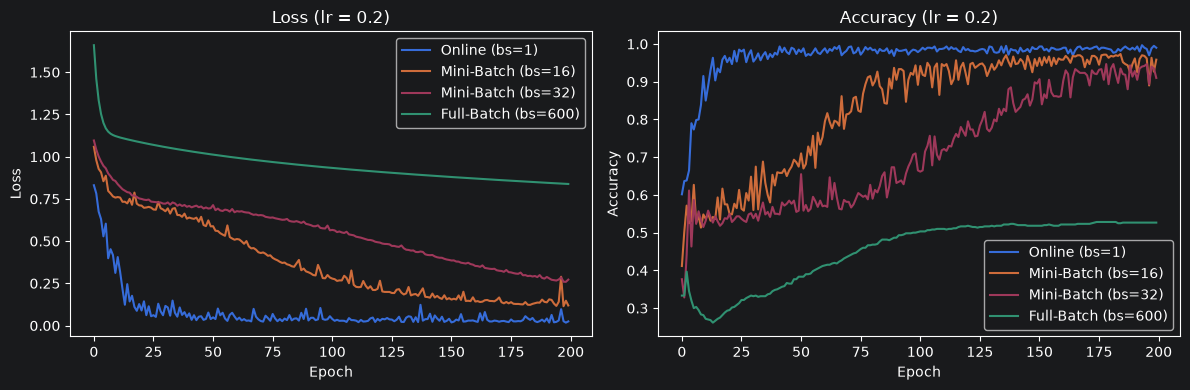

In [8]:
configs = [
    ("Online (bs=1)", None),
    ("Mini-Batch (bs=16)", 16),
    ("Mini-Batch (bs=32)", 32),
    ("Full-Batch (bs=600)", len(X)),
]

histories_lr02 = {}

for label, bs in configs:
    np.random.seed(42)  # same initial weights for fair comparison
    model = MLP(input_dim=input_dim, layer_sizes=layer_sizes, num_classes=num_classes, seed=42)
    
    start_time = time.time()
    if bs is None:
        hist = train_online_learning(model, X, y, epochs=200, lr=0.2, seed=123, verbose=False)
    else:
        hist = train_batch_learning(model, X, y, epochs=200, batch_size=bs, lr=0.2, seed=123, verbose=False)
    elapsed = time.time() - start_time
    
    histories_lr02[label] = hist
    print(f"{label:20s} | final loss={hist['loss'][-1]:.4f} | final acc={hist['acc'][-1]*100:.2f}% | time={elapsed:.2f}s")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for label, hist in histories_lr02.items():
    plt.plot(hist["loss"], label=label)
plt.title("Loss (lr = 0.2)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
for label, hist in histories_lr02.items():
    plt.plot(hist["acc"], label=label)
plt.title("Accuracy (lr = 0.2)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


### 3.2 Stability comparison at a higher learning rate (`lr = 1.0`)

Online (lr=1.0)     | final loss=0.1459 | final acc=93.50%
Batch bs=32 (lr=1.0)| final loss=0.0385 | final acc=98.33%


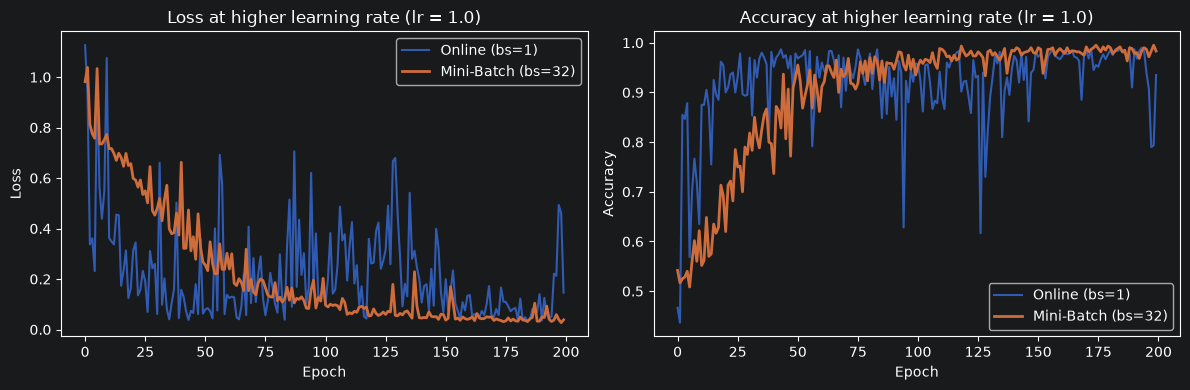

In [9]:
np.random.seed(42)
model_online_high_lr = MLP(input_dim=input_dim, layer_sizes=layer_sizes, num_classes=num_classes, seed=42)
hist_online_high = train_online_learning(model_online_high_lr, X, y, epochs=200, lr=1.0, seed=123, verbose=False)

np.random.seed(42)
model_batch_high_lr = MLP(input_dim=input_dim, layer_sizes=layer_sizes, num_classes=num_classes, seed=42)
hist_batch_high = train_batch_learning(model_batch_high_lr, X, y, epochs=200, batch_size=32, lr=1.0, seed=123, verbose=False)

print(f"Online (lr=1.0)     | final loss={hist_online_high['loss'][-1]:.4f} | final acc={hist_online_high['acc'][-1]*100:.2f}%")
print(f"Batch bs=32 (lr=1.0)| final loss={hist_batch_high['loss'][-1]:.4f} | final acc={hist_batch_high['acc'][-1]*100:.2f}%")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_online_high["loss"], label="Online (bs=1)", alpha=0.8)
plt.plot(hist_batch_high["loss"], label="Mini-Batch (bs=32)", linewidth=2)
plt.title("Loss at higher learning rate (lr = 1.0)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_online_high["acc"], label="Online (bs=1)", alpha=0.8)
plt.plot(hist_batch_high["acc"], label="Mini-Batch (bs=32)", linewidth=2)
plt.title("Accuracy at higher learning rate (lr = 1.0)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


### 3.3 Discussion

- **Variance and learning stability:**
    - **Online learning** gets the gradient from a single sample at a time. These samples contain noise and can contradict each other. Because of this, the updates have a high variance. There are visible spikes after each epoch in the online learning algorithm.
    - **Batched learning** averages the gradient form multiple samples and then updates w and b. This leads to a much smoother and stable curve in the loss and accuracy
- **Behavior with higher learning rates (`lr = 1.0`):**
    - Because mini-batches are much more stable, the high learning rate does not affect the curve that much. This makes the method still very usable and safe for usage with the high lr.
    - The online learning does have an incredible high variance with this learning rate. This makes it not very usable, as the learning becomes very unstable
- **Mini-Batch vs. Full-Batch:**
    - Full-batch learning has no noise at all, so it gets stuck in a flat plateau.
    - Mini-batch learning keeps enough noise between batches to escape flat regions while still converging smoothly, making it way more useful than full-batch
- **Other observations:**
    - as already stated in the assignment, the online learning converges way faster to a high accuracy and low loss.
    - The online learning is computationally way more expensive (10+ seconds)

# AI Usage / Prompts:
- create two visualizations comparing the two functions (train_online_learning and train_batch_learning) with the y-axis being loss/accuracy and x-axis being the epoch. Use the spiral dataset generator provided: """..."""